# Student Performance Analysis Using Python
## Exploratory Data Analysis (EDA)

### 1. Introduction
This project analyzes student exam performance using Python. The dataset (*Students Performance in Exams*) contains 1,000 student records with mathematics, reading and writing scores, along with background details such as gender, parental education, lunch type and test-preparation course.

### 2. Objectives
- Understand the dataset structure and columns.
- Check for missing values and duplicate records.
- Calculate average marks and summary statistics.
- Compare scores by gender and test-preparation course.
- Identify patterns in student performance.

### 3. Tools Used
Python, Google Colab, Pandas, Matplotlib

## 4. Load the Dataset

In [1]:
import zipfile
import os
import pandas as pd
import matplotlib.pyplot as plt

zip_path = "/content/archive.zip"
extract_path = "/content/student_data"

# Extract the dataset (upload archive.zip to Colab first)
if os.path.exists(zip_path):
    with zipfile.ZipFile(zip_path, "r") as z:
        z.extractall(extract_path)

df = pd.read_csv(os.path.join(extract_path, "StudentsPerformance.csv"))

print("Dataset loaded successfully!")
print("Number of rows and columns:", df.shape)
display(df.head())

Dataset loaded successfully!
Number of rows and columns: (1000, 8)


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


## 5. Dataset Structure

In [2]:
print("Column Names:")
print(df.columns.tolist())
print()
df.info()

Dataset Information
--------------------
Number of rows and columns: (1000, 8)

Column Names:
['gender', 'race/ethnicity', 'parental level of education', 'lunch', 'test preparation course', 'math score', 'reading score', 'writing score']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype 
---  ------                       --------------  ----- 
 0   gender                       1000 non-null   object
 1   race/ethnicity               1000 non-null   object
 2   parental level of education  1000 non-null   object
 3   lunch                        1000 non-null   object
 4   test preparation course      1000 non-null   object
 5   math score                   1000 non-null   int64 
 6   reading score                1000 non-null   int64 
 7   writing score                1000 non-null   int64 
dtypes: int64(3), object(5)
memory usage: 62.6+ KB


## 6. Data Quality Checks
### Missing values

In [3]:
print("Missing Values in Each Column:")
print(df.isnull().sum())

Missing Values in Each Column:
gender                         0
race/ethnicity                 0
parental level of education    0
lunch                          0
test preparation course        0
math score                     0
reading score                  0
writing score                  0
dtype: int64


### Duplicate rows

In [4]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


### Invalid scores (outside 0–100)

In [5]:
subjects = ["math score", "reading score", "writing score"]

for subject in subjects:
    invalid = df[(df[subject] < 0) | (df[subject] > 100)]
    print(subject, "- Invalid scores:", len(invalid))

math score - Invalid scores: 0
reading score - Invalid scores: 0
writing score - Invalid scores: 0


## 7. Summary Statistics

In [6]:
print("Average Exam Scores")
print("-------------------")
print("Math score:", df["math score"].mean())
print("Reading score:", df["reading score"].mean())
print("Writing score:", df["writing score"].mean())

Average Exam Scores
-------------------
Math score: 66.089
Reading score: 69.169
Writing score: 68.054


In [7]:
display(df[subjects].describe())

,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000


In [8]:
print("Minimum and Maximum Scores:")
display(df[subjects].agg(["min", "max"]))

Minimum and Maximum Scores:


,math score,reading score,writing score
min,0,17,10
max,100,100,100


## 8. Group Comparisons
### Scores by gender

In [9]:
gender_scores = df.groupby("gender")[subjects].mean()
print("Average Scores by Gender:")
display(gender_scores.round(2))

Average Scores by Gender:


,math score,reading score,writing score
gender,,,
female,63.63,72.61,72.47
male,68.73,65.47,63.31


### Scores by test-preparation course

In [10]:
prep_scores = df.groupby("test preparation course")[subjects].mean()
print("Average Scores by Test Preparation Course:")
display(prep_scores.round(2))

Average Scores by Test Preparation Course:


,math score,reading score,writing score
test preparation course,,,
completed,69.70,73.89,74.42
none,64.08,66.53,64.50


## 9. Visualizations
### Average score by subject

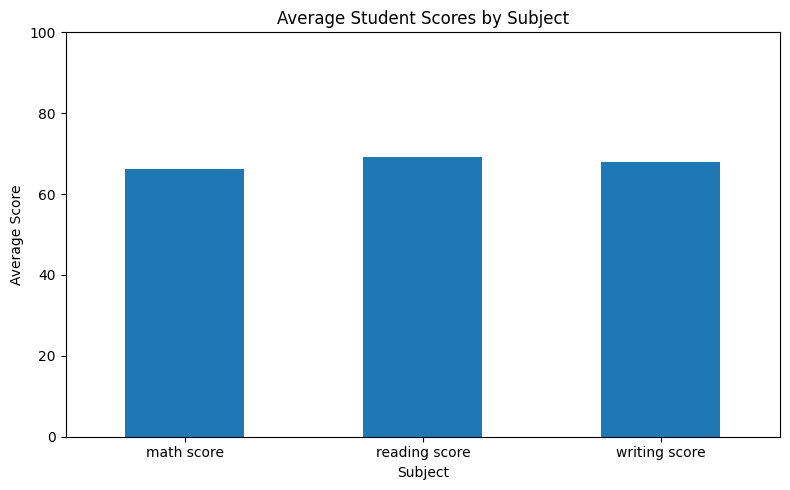

In [11]:
average_scores = df[subjects].mean()

plt.figure(figsize=(8, 5))
average_scores.plot(kind="bar")
plt.title("Average Student Scores by Subject")
plt.xlabel("Subject")
plt.ylabel("Average Score")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.tight_layout()
plt.show()

### Scores by test-preparation course

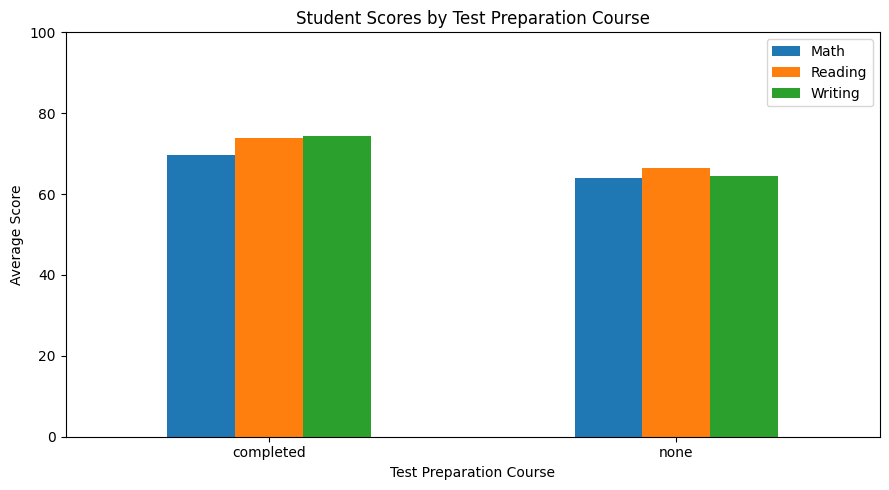

In [12]:
prep_scores.plot(kind="bar", figsize=(9, 5))
plt.title("Student Scores by Test Preparation Course")
plt.xlabel("Test Preparation Course")
plt.ylabel("Average Score")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(["Math", "Reading", "Writing"])
plt.tight_layout()
plt.show()

## 10. Key Findings
- The dataset has **1,000 rows and 8 columns**, with **no missing values**, **no duplicates** and **no invalid scores**.
- Average scores: **Math 66.09, Reading 69.17, Writing 68.05**. Reading is the strongest subject overall.
- **Gender:** female students scored higher in reading (72.61 vs 65.47) and writing (72.47 vs 63.31); male students scored higher in math (68.73 vs 63.63).
- **Test preparation:** students who completed the course scored higher in all three subjects (e.g. writing 74.42 vs 64.50).

## 11. Conclusion
Exploratory Data Analysis was performed on the Students Performance in Exams dataset. The data was clean and ready for analysis. The results show that test preparation is associated with higher scores in every subject, and that gender differences vary by subject. These are patterns in this dataset, not proof of cause and effect. Further analysis could include parental education, lunch type and correlation between subjects.